In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random

from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models

In [2]:
train_path = r"C:\Users\slava\Downloads\archive (61)\train"
test_path  = r"C:\Users\slava\Downloads\archive (61)\test"

In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [4]:
train_dataset = image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="training",
    seed=SEED
)

validation_dataset = image_dataset_from_directory(
    train_path,image_size=IMG_SIZE,batch_size=BATCH_SIZE,
    validation_split=0.20,subset="validation",seed=SEED
)

test_dataset = image_dataset_from_directory(
    test_path,image_size=IMG_SIZE,batch_size=BATCH_SIZE,
    shuffle=False
)

Found 59152 files belonging to 36 classes.
Using 47322 files for training.
Found 59152 files belonging to 36 classes.
Using 11830 files for validation.
Found 12705 files belonging to 36 classes.


In [5]:
class_names = train_dataset.class_names

print("Number of Classes:", len(class_names))
print("\nDisease Classes:")

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of Classes: 36

Disease Classes:
0 : Bell_pepper__Bell_pepper_Bacterial_spot
1 : Bell_pepper__Bell_pepper_Healthy
2 : Brinjal__Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot
3 : Brinjal__Fresh_Brinjal_Leaf
4 : Cabbage__Alternaria_Leaf_Spot
5 : Cabbage__Bacterial_spot_rot
6 : Cabbage__Black_Rot
7 : Cabbage__Cabbage_aphid_colony
8 : Cabbage__Downy_Mildew
9 : Cabbage__Healthy
10 : Cabbage__club_root
11 : Cabbage__ring_spot
12 : Citrus__Citrus_Black_spot
13 : Citrus__Citrus_Healthy
14 : Citrus__Citrus_canker
15 : Citrus__Citrus_greening
16 : Corn__Corn_Common_rust
17 : Corn__Corn_Gray_leaf_spot
18 : Corn__Corn_Healthy
19 : Corn__Corn_Northern_Leaf_Blight
20 : Lettuce__Bacterial
21 : Lettuce__fungal
22 : Lettuce__healthy
23 : Potato__Potato_Early_blight
24 : Potato__Potato_Healthy
25 : Potato__Potato_Late_blight
26 : Tomato__Tomato_Bacterial_spot
27 : Tomato__Tomato_Early_blight
28 : Tomato__Tomato_Healthy
29 : Tomato__Tomato_Late_blight
30 : Tomato__Tomato_Leaf_Mold
31 : Tomato__Tomat

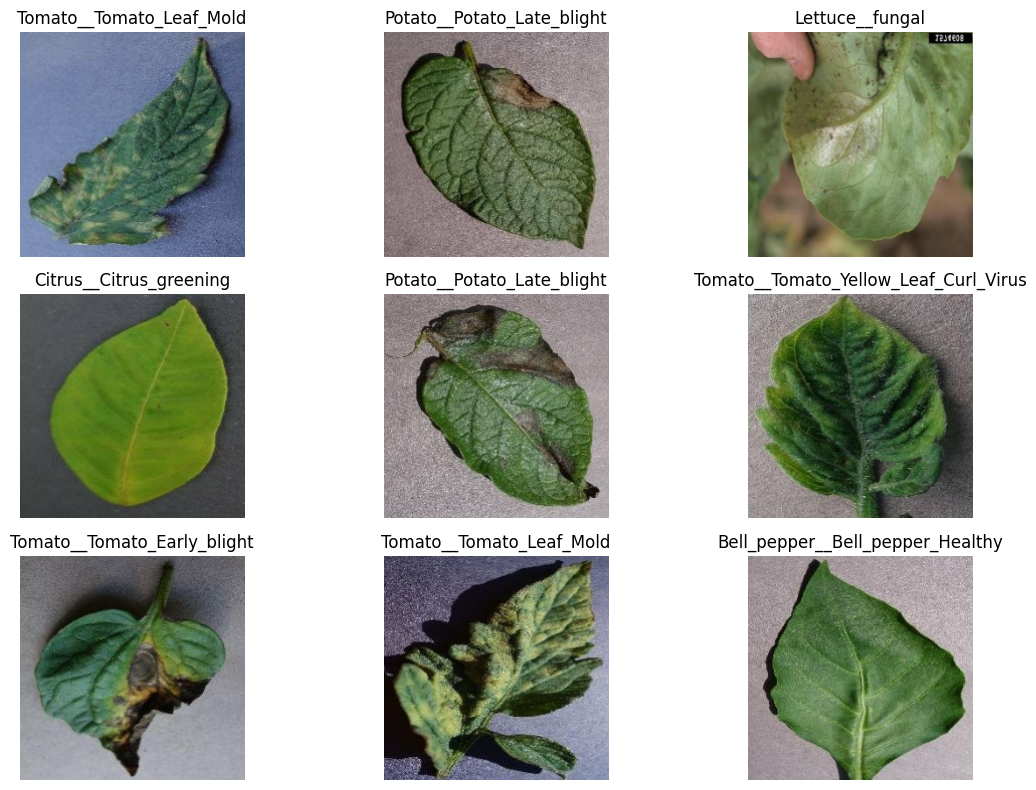

In [6]:
plt.figure(figsize=(12, 8))

for images, labels in train_dataset.take(1):

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

In [8]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [9]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)


base_model.trainable = False

In [10]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(
        1./127.5,
        offset=-1
    ),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(
        128,
        activation="relu"
    ),
    layers.Dropout(0.3),
    layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

In [11]:
model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 36)                  │           4,644 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,426,596 (9.26 MB)

 Trainable params: 168,612 (658.64 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=2
)

Epoch 1/2


C:\Users\slava\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1479/1479 ━━━━━━━━━━━━━━━━━━━━ 2603s 2s/step - accuracy: 0.7776 - loss: 0.7240 - val_accuracy: 0.8555 - val_loss: 0.4310
Epoch 2/2
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 1447s 978ms/step - accuracy: 0.8575 - loss: 0.4365 - val_accuracy: 0.8845 - val_loss: 0.3413


In [13]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=2
)

Epoch 1/2
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 1766s 1s/step - accuracy: 0.8975 - loss: 0.3085 - val_accuracy: 0.9078 - val_loss: 0.2757
Epoch 2/2
1479/1479 ━━━━━━━━━━━━━━━━━━━━ 1293s 874ms/step - accuracy: 0.9163 - loss: 0.2542 - val_accuracy: 0.9083 - val_loss: 0.2696


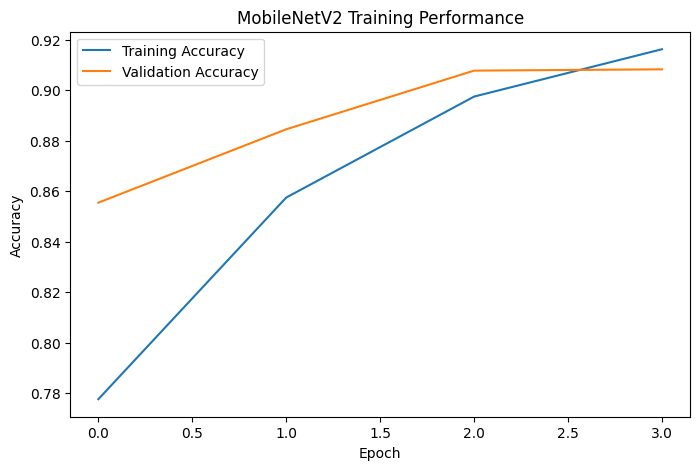

In [14]:
train_accuracy = (
    history.history["accuracy"] + history2.history["accuracy"]
)
val_accuracy = (
    history.history["val_accuracy"] + history2.history["val_accuracy"]
)

plt.figure(figsize=(8, 5))
plt.plot(train_accuracy, label="Training Accuracy")
plt.plot(val_accuracy, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Training Performance")
plt.legend()
plt.show()

In [15]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

398/398 ━━━━━━━━━━━━━━━━━━━━ 211s 530ms/step - accuracy: 0.9115 - loss: 0.2606
Test Loss: 0.2606
Test Accuracy: 91.15 %


398/398 ━━━━━━━━━━━━━━━━━━━━ 202s 503ms/step
                                                       precision    recall  f1-score   support

              Bell_pepper__Bell_pepper_Bacterial_spot       0.97      0.96      0.96       518
                     Bell_pepper__Bell_pepper_Healthy       0.96      0.98      0.97       603
Brinjal__Diseased_Brinjal_Leaf_-_Cercospora_Leaf_Spot       0.99      0.91      0.95       157
                          Brinjal__Fresh_Brinjal_Leaf       0.90      1.00      0.95       178
                        Cabbage__Alternaria_Leaf_Spot       0.79      0.77      0.78        30
                          Cabbage__Bacterial_spot_rot       1.00      0.93      0.97        30
                                   Cabbage__Black_Rot       0.90      0.90      0.90        30
                        Cabbage__Cabbage_aphid_colony       1.00      0.77      0.87        30
                                Cabbage__Downy_Mildew       0.61      0.83      0.70        30
    

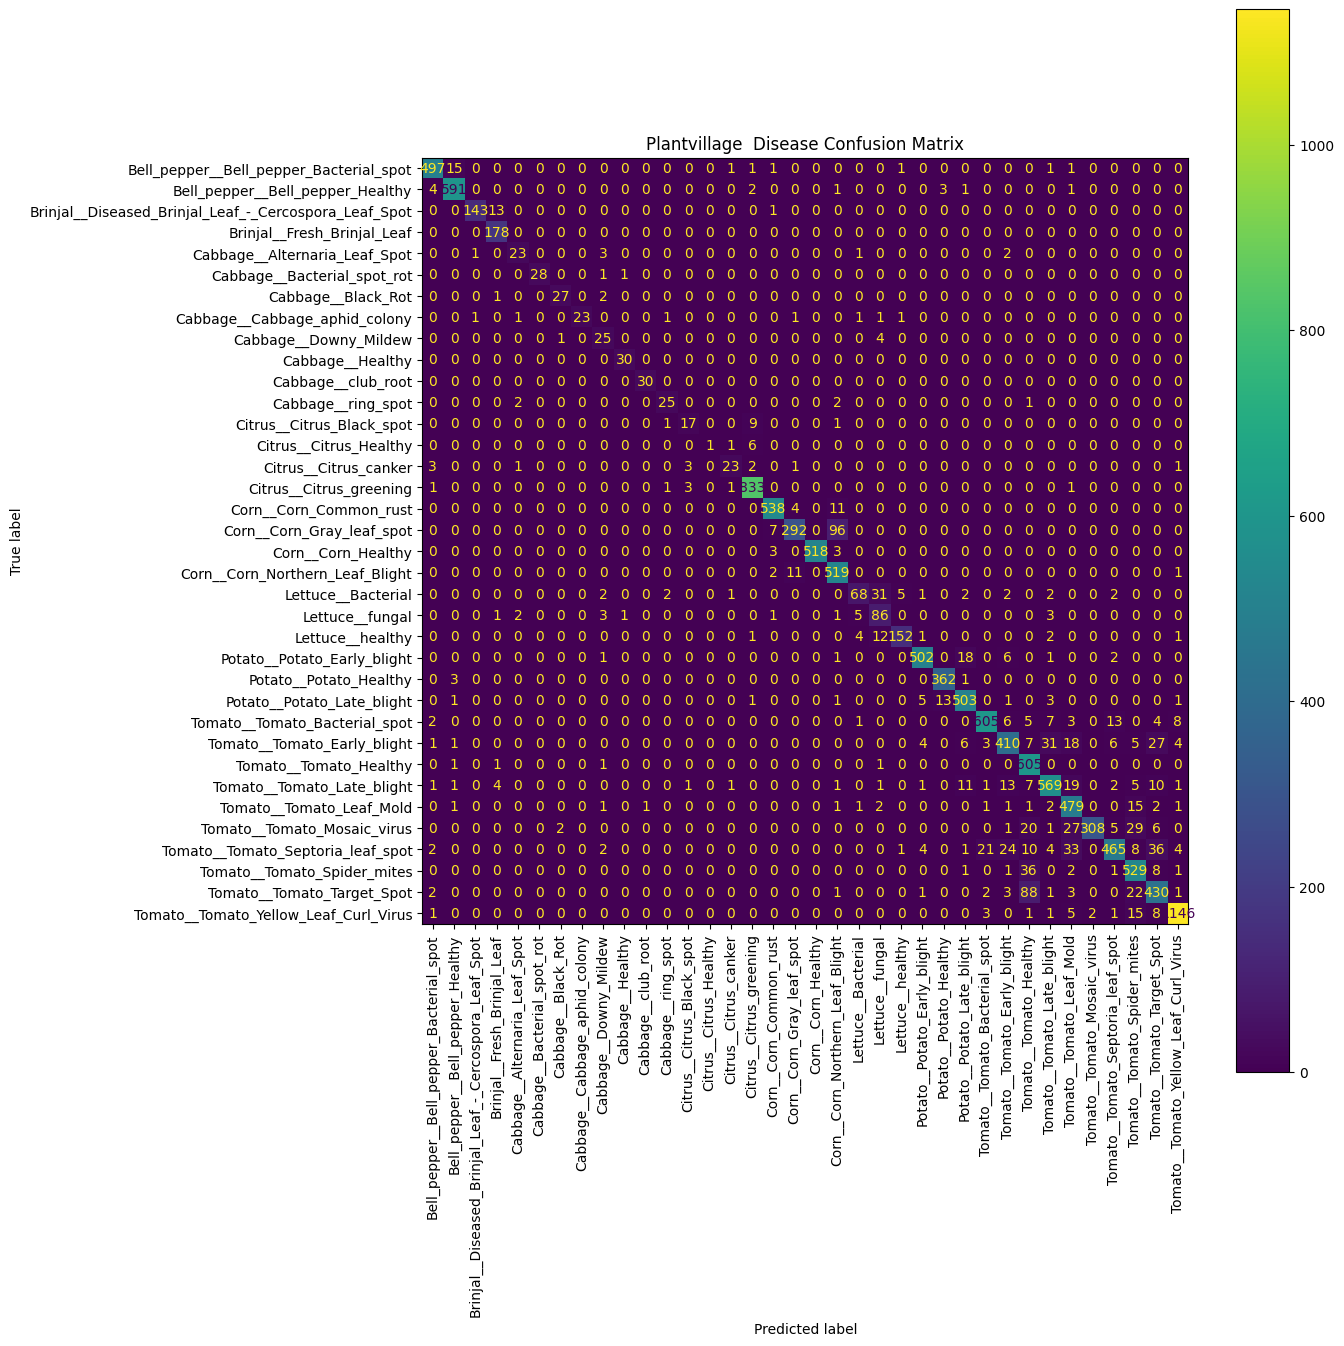

In [16]:
from sklearn.metrics import(classification_report,confusion_matrix,ConfusionMatrixDisplay)

NUM_CLASSES = len(class_names)
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

y_prob = model.predict(test_dataset)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,y_pred,
    labels=list(range(NUM_CLASSES)))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(14, 14))
disp.plot(ax=ax, xticks_rotation="vertical", values_format="d")
plt.title("Plantvillage  Disease Confusion Matrix")
plt.tight_layout()
plt.show()

In [17]:
model.save("plantvillage_disease_mobilenetv2.keras")
print("Model saved successfully!")

Model saved successfully!
